Cell 1 — Import Python libraries

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import numpy as np
import time

from torchvision import datasets, transforms
from torch.utils.data import DataLoader

# Select GPU if available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Set random seeds
torch.manual_seed(42)
np.random.seed(42)

print("Using device:", device)

Using device: cuda


Cell 2: Load the MNIST dataset

## Interval Analysis

In [ ]:
# Load MNIST dataset

transform = transforms.ToTensor()

train_dataset = datasets.MNIST(
    root="mnist_data/",
    train=True,
    download=True,
    transform=transform
)

test_dataset = datasets.MNIST(
    root="mnist_data/",
    train=False,
    download=True,
    transform=transform
)

# Create data loaders
batch_size = 64

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False
)

print("Training images:", len(train_dataset))
print("Testing images:", len(test_dataset))
print("Batch size:", batch_size)

Training images: 60000
Testing images: 10000
Batch size: 64


Cell 3: Build the neural network

In [ ]:
# Define the neural network for HW4 Problem 1

class MNISTNetwork(nn.Module):
    def __init__(self):
        super().__init__()

        self.fc1 = nn.Linear(784, 50)
        self.fc2 = nn.Linear(50, 50)
        self.fc3 = nn.Linear(50, 50)
        self.fc4 = nn.Linear(50, 10)

    def forward(self, x):
        x = x.view(x.size(0), -1)

        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        x = F.relu(self.fc3(x))
        x = self.fc4(x)

        return x

# Create the model and move it to GPU
model = MNISTNetwork().to(device)

print(model)

MNISTNetwork(
  (fc1): Linear(in_features=784, out_features=50, bias=True)
  (fc2): Linear(in_features=50, out_features=50, bias=True)
  (fc3): Linear(in_features=50, out_features=50, bias=True)
  (fc4): Linear(in_features=50, out_features=10, bias=True)
)


Cell 4: Train the standard neural network

In [ ]:
# Cell 4: Standard neural network training

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

epochs = 10

# Record training time
start_time = time.perf_counter()

for epoch in range(epochs):
    model.train()
    running_loss = 0.0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        # Clear previous gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = model(images)

        # Calculate cross-entropy loss
        loss = criterion(outputs, labels)

        # Backpropagation
        loss.backward()

        # Update weights
        optimizer.step()

        running_loss += loss.item() * images.size(0)

    average_loss = running_loss / len(train_dataset)

    print(
        f"Epoch {epoch+1}/{epochs}, "
        f"Loss: {average_loss:.4f}"
    )

# Measure total training time
if device.type == "cuda":
    torch.cuda.synchronize()

standard_training_time = time.perf_counter() - start_time

print(f"\nStandard training time: {standard_training_time:.2f} seconds")

Epoch 1/10, Loss: 0.4271
Epoch 2/10, Loss: 0.1819
Epoch 3/10, Loss: 0.1382
Epoch 4/10, Loss: 0.1112
Epoch 5/10, Loss: 0.0907
Epoch 6/10, Loss: 0.0815
Epoch 7/10, Loss: 0.0723
Epoch 8/10, Loss: 0.0627
Epoch 9/10, Loss: 0.0541
Epoch 10/10, Loss: 0.0499

Standard training time: 84.22 seconds


Cell 5: Evaluate standard accuracy

In [ ]:

# Cell 5: Evaluate standard accuracy

model.eval()

correct = 0
total = 0

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        # Make predictions
        outputs = model(images)

        # Select the class with the highest score
        predicted = outputs.argmax(dim=1)

        # Count correct predictions
        correct += (predicted == labels).sum().item()
        total += labels.size(0)

standard_accuracy = 100 * correct / total

print("Correct predictions:", correct)
print("Total test images:", total)
print(f"Standard accuracy: {standard_accuracy:.2f}%")


Correct predictions: 9715
Total test images: 10000
Standard accuracy: 97.15%


Cell 6: Implement Interval Bound Propagation (IBP)

In [ ]:

# Cell 6: Interval Bound Propagation (IBP)

def linear_ibp(lower, upper, layer):
    W = layer.weight
    b = layer.bias

    W_pos = torch.clamp(W, min=0)
    W_neg = torch.clamp(W, max=0)

    lower_new = (
        F.linear(lower, W_pos)
        + F.linear(upper, W_neg)
        + b
    )

    upper_new = (
        F.linear(upper, W_pos)
        + F.linear(lower, W_neg)
        + b
    )

    return lower_new, upper_new


def ibp_forward(model, images, epsilon):
    x = images.view(images.size(0), -1)

    lower = torch.clamp(x - epsilon, 0, 1)
    upper = torch.clamp(x + epsilon, 0, 1)

    for layer in [model.fc1, model.fc2, model.fc3]:
        lower, upper = linear_ibp(lower, upper, layer)

        lower = F.relu(lower)
        upper = F.relu(upper)

    lower, upper = linear_ibp(lower, upper, model.fc4)

    return lower, upper


# Test the IBP implementation
images, labels = next(iter(test_loader))
images = images.to(device)

lower, upper = ibp_forward(model, images, epsilon=0.01)

print("Lower bound shape:", lower.shape)
print("Upper bound shape:", upper.shape)
print("All lower <= upper:", bool(torch.all(lower <= upper)))


Lower bound shape: torch.Size([64, 10])
Upper bound shape: torch.Size([64, 10])
All lower <= upper: True


Cell 7: Implement the IBP robustness loss

In [ ]:

# Cell 7: IBP robustness loss

def ibp_robust_loss(model, images, labels, epsilon):
    x = images.view(images.size(0), -1)

    # Initial input bounds
    lower = torch.clamp(x - epsilon, 0, 1)
    upper = torch.clamp(x + epsilon, 0, 1)

    # Propagate through the three hidden layers
    for layer in [model.fc1, model.fc2, model.fc3]:
        lower, upper = linear_ibp(lower, upper, layer)
        lower = F.relu(lower)
        upper = F.relu(upper)

    # Last layer: compare true class with other classes
    W = model.fc4.weight
    b = model.fc4.bias

    W_true = W[labels]
    b_true = b[labels]

    # Difference: competing class minus true class
    W_diff = W.unsqueeze(0) - W_true.unsqueeze(1)
    b_diff = b.unsqueeze(0) - b_true.unsqueeze(1)

    W_pos = torch.clamp(W_diff, min=0)
    W_neg = torch.clamp(W_diff, max=0)

    # Upper bounds on competing-class score differences
    worst_logits = (
        torch.einsum("bch,bh->bc", W_pos, upper)
        + torch.einsum("bch,bh->bc", W_neg, lower)
        + b_diff
    )

    # True-class difference is exactly zero
    worst_logits = worst_logits.scatter(
        1, labels.unsqueeze(1), 0.0
    )

    # Cross-entropy with true-class logit fixed at zero
    return F.cross_entropy(worst_logits, labels)


# Test the robustness loss
images, labels = next(iter(train_loader))
images = images.to(device)
labels = labels.to(device)

robust_loss = ibp_robust_loss(
    model, images, labels, epsilon=0.01
)

print("IBP robustness loss:", robust_loss.item())
print("Loss is finite:", bool(torch.isfinite(robust_loss)))


IBP robustness loss: 40.56687927246094
Loss is finite: True


Cell 8: Train the IBP neural network

In [ ]:

# Cell 8: IBP training with kappa and epsilon schedules

# Create a new model with the same architecture
torch.manual_seed(42)
ibp_model = MNISTNetwork().to(device)

ibp_optimizer = optim.Adam(ibp_model.parameters(), lr=0.001)
criterion = nn.CrossEntropyLoss()

ibp_epochs = 10

# Synchronize GPU before starting the timer
if device.type == "cuda":
    torch.cuda.synchronize()

start_time = time.perf_counter()

for epoch in range(ibp_epochs):

    ibp_model.train()
    running_loss = 0.0

    # Gradually change both parameters
    progress = epoch / (ibp_epochs - 1)

    kappa = 1.0 - 0.5 * progress
    epsilon_train = 0.1 * progress

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        ibp_optimizer.zero_grad()

        # Standard classification loss
        outputs = ibp_model(images)
        standard_loss = criterion(outputs, labels)

        # IBP robustness loss
        robust_loss = ibp_robust_loss(
            ibp_model, images, labels, epsilon_train
        )

        # Combined IBP loss
        loss = (
            kappa * standard_loss
            + (1 - kappa) * robust_loss
        )

        loss.backward()
        ibp_optimizer.step()

        running_loss += loss.item() * images.size(0)

    average_loss = running_loss / len(train_dataset)

    print(
        f"Epoch {epoch+1}/{ibp_epochs}, "
        f"Kappa: {kappa:.3f}, "
        f"Epsilon: {epsilon_train:.3f}, "
        f"Loss: {average_loss:.4f}"
    )

if device.type == "cuda":
    torch.cuda.synchronize()

ibp_training_time = time.perf_counter() - start_time

print(f"\nIBP training time: {ibp_training_time:.2f} seconds")
print(f"Standard training time: {standard_training_time:.2f} seconds")
print(f"Time ratio: {ibp_training_time / standard_training_time:.2f}x")


Epoch 1/10, Kappa: 1.000, Epsilon: 0.000, Loss: 0.4271
Epoch 2/10, Kappa: 0.944, Epsilon: 0.011, Loss: 0.3015
Epoch 3/10, Kappa: 0.889, Epsilon: 0.022, Loss: 0.2926
Epoch 4/10, Kappa: 0.833, Epsilon: 0.033, Loss: 0.2959
Epoch 5/10, Kappa: 0.778, Epsilon: 0.044, Loss: 0.3143
Epoch 6/10, Kappa: 0.722, Epsilon: 0.056, Loss: 0.3466
Epoch 7/10, Kappa: 0.667, Epsilon: 0.067, Loss: 0.3940
Epoch 8/10, Kappa: 0.611, Epsilon: 0.078, Loss: 0.4572
Epoch 9/10, Kappa: 0.556, Epsilon: 0.089, Loss: 0.5289
Epoch 10/10, Kappa: 0.500, Epsilon: 0.100, Loss: 0.6100

IBP training time: 121.82 seconds
Standard training time: 84.22 seconds
Time ratio: 1.45x


Cell 9: Evaluate IBP standard accuracy

In [ ]:

# Cell 9: Evaluate IBP model standard accuracy

ibp_model.eval()

correct = 0
total = 0

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = ibp_model(images)
        predicted = outputs.argmax(dim=1)

        correct += (predicted == labels).sum().item()
        total += labels.size(0)

ibp_standard_accuracy = 100 * correct / total

print("Correct predictions:", correct)
print("Total test images:", total)
print(f"IBP standard accuracy: {ibp_standard_accuracy:.2f}%")

print("\nComparison:")
print(f"Standard model accuracy: {standard_accuracy:.2f}%")
print(f"IBP model accuracy: {ibp_standard_accuracy:.2f}%")
print(
    f"Accuracy difference: "
    f"{ibp_standard_accuracy - standard_accuracy:+.2f} percentage points"
)


Correct predictions: 9437
Total test images: 10000
IBP standard accuracy: 94.37%

Comparison:
Standard model accuracy: 97.15%
IBP model accuracy: 94.37%
Accuracy difference: -2.78 percentage points


Cell 10: Implement the PGD attack

In [ ]:

# Cell 10: PGD L-infinity attack

def pgd_attack(model, images, labels,
               epsilon=0.1, alpha=0.01, steps=40):

    model.eval()

    original_images = images.detach()

    # Random starting point inside epsilon ball
    adv_images = original_images + torch.empty_like(
        original_images
    ).uniform_(-epsilon, epsilon)

    adv_images = torch.clamp(adv_images, 0, 1).detach()

    for step in range(steps):
        adv_images.requires_grad_(True)

        outputs = model(adv_images)
        loss = F.cross_entropy(outputs, labels)

        gradient = torch.autograd.grad(
            loss, adv_images
        )[0]

        # Move pixels in direction that increases loss
        adv_images = adv_images.detach() + alpha * gradient.sign()

        # Project back into allowed epsilon region
        perturbation = torch.clamp(
            adv_images - original_images,
            min=-epsilon,
            max=epsilon
        )

        adv_images = torch.clamp(
            original_images + perturbation, 0, 1
        ).detach()

    return adv_images


print("PGD attack function created successfully.")


PGD attack function created successfully.


# **Cell 11: Calculate PGD robust accuracy**

In [ ]:

# Cell 11: Evaluate PGD robust accuracy

def evaluate_pgd(model, test_loader,
                 epsilon=0.1, alpha=0.01,
                 steps=40, restarts=3):

    model.eval()

    robust_correct = 0
    total = 0

    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        # First check clean predictions
        with torch.no_grad():
            clean_predictions = model(images).argmax(dim=1)
            still_correct = clean_predictions.eq(labels)

        # Multiple PGD attempts
        for restart in range(restarts):
            adv_images = pgd_attack(
                model, images, labels,
                epsilon=epsilon,
                alpha=alpha,
                steps=steps
            )

            with torch.no_grad():
                adv_predictions = model(adv_images).argmax(dim=1)

            # Must survive every attack
            still_correct &= adv_predictions.eq(labels)

        robust_correct += still_correct.sum().item()
        total += labels.size(0)

    return 100 * robust_correct / total


print("Evaluating standard model...")
standard_pgd_accuracy = evaluate_pgd(
    model, test_loader
)

print(f"Standard model PGD accuracy: {standard_pgd_accuracy:.2f}%")

print("\nEvaluating IBP model...")
ibp_pgd_accuracy = evaluate_pgd(
    ibp_model, test_loader
)

print(f"IBP model PGD accuracy: {ibp_pgd_accuracy:.2f}%")

print("\nPGD robustness comparison:")
print(f"Standard model: {standard_pgd_accuracy:.2f}%")
print(f"IBP model: {ibp_pgd_accuracy:.2f}%")
print(
    f"Difference: "
    f"{ibp_pgd_accuracy - standard_pgd_accuracy:+.2f} percentage points"
)


Evaluating standard model...
Standard model PGD accuracy: 1.26%

Evaluating IBP model...
IBP model PGD accuracy: 81.48%

PGD robustness comparison:
Standard model: 1.26%
IBP model: 81.48%
Difference: +80.22 percentage points


Cell 12: Verified Accuracy**

In [ ]:

# Cell 12: Verified Accuracy with Tighter IBP Bounds

def evaluate_verified_accuracy(model, test_loader, epsilon):
    model.eval()

    verified_correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in test_loader:
            images = images.to(device)
            labels = labels.to(device)

            # Input intervals
            x = images.view(images.size(0), -1)
            lower = torch.clamp(x - epsilon, 0, 1)
            upper = torch.clamp(x + epsilon, 0, 1)

            # Propagate through hidden layers
            for layer in [model.fc1, model.fc2, model.fc3]:
                lower, upper = linear_ibp(lower, upper, layer)
                lower = F.relu(lower)
                upper = F.relu(upper)

            # Merge last layer into class differences
            W = model.fc4.weight
            b = model.fc4.bias

            W_true = W[labels]
            b_true = b[labels]

            W_diff = W.unsqueeze(0) - W_true.unsqueeze(1)
            b_diff = b.unsqueeze(0) - b_true.unsqueeze(1)

            W_pos = torch.clamp(W_diff, min=0)
            W_neg = torch.clamp(W_diff, max=0)

            worst_logits = (
                torch.einsum("bch,bh->bc", W_pos, upper)
                + torch.einsum("bch,bh->bc", W_neg, lower)
                + b_diff
            )

            # Ignore true-class comparison
            worst_logits.scatter_(
                1, labels.unsqueeze(1), float("-inf")
            )

            # Certified if all competing differences are negative
            certified = worst_logits.max(dim=1).values < 0

            verified_correct += certified.sum().item()
            total += labels.size(0)

    return 100 * verified_correct / total


# Evaluate epsilon values from 0.01 to 0.10
epsilon_values = [i / 100 for i in range(1, 11)]
verified_results = []

print("Verified accuracy using tighter IBP bounds")
print("-" * 45)

for eps in epsilon_values:
    accuracy = evaluate_verified_accuracy(
        ibp_model, test_loader, eps
    )

    verified_results.append(accuracy)

    print(
        f"Epsilon: {eps:.2f}, "
        f"Verified accuracy: {accuracy:.2f}%"
    )


Verified accuracy using tighter IBP bounds
---------------------------------------------
Epsilon: 0.01, Verified accuracy: 93.38%
Epsilon: 0.02, Verified accuracy: 92.31%
Epsilon: 0.03, Verified accuracy: 91.07%
Epsilon: 0.04, Verified accuracy: 89.68%
Epsilon: 0.05, Verified accuracy: 88.16%
Epsilon: 0.06, Verified accuracy: 86.42%
Epsilon: 0.07, Verified accuracy: 84.18%
Epsilon: 0.08, Verified accuracy: 81.60%
Epsilon: 0.09, Verified accuracy: 78.72%
Epsilon: 0.10, Verified accuracy: 75.15%


# **Cell 13: Find and display adversarial examples**

Found 5 successful adversarial examples


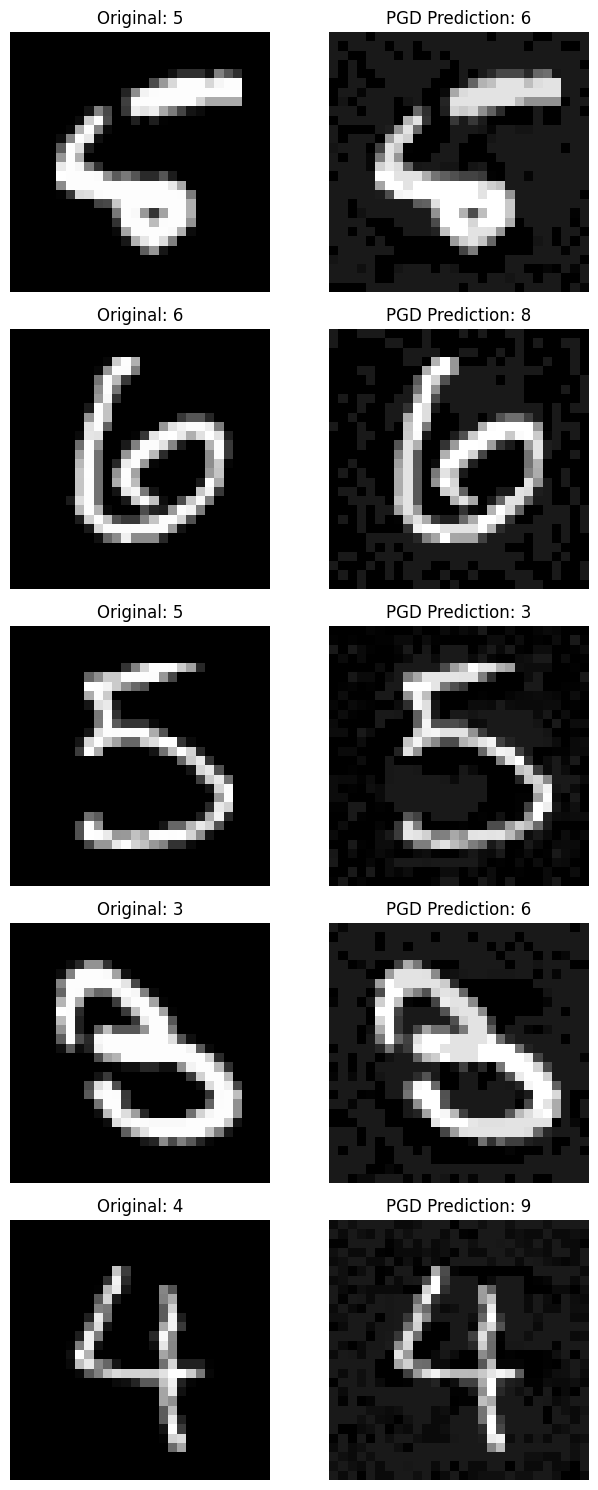

In [ ]:

# Cell 13: Find and Display PGD Adversarial Examples

import matplotlib.pyplot as plt

ibp_model.eval()
epsilon = 0.10
examples = []

for images, labels in test_loader:
    images = images.to(device)
    labels = labels.to(device)

    # Step 1: Calculate tighter IBP bounds
    with torch.no_grad():
        x = images.view(images.size(0), -1)
        lower = torch.clamp(x - epsilon, 0, 1)
        upper = torch.clamp(x + epsilon, 0, 1)

        for layer in [ibp_model.fc1, ibp_model.fc2, ibp_model.fc3]:
            lower, upper = linear_ibp(lower, upper, layer)
            lower = F.relu(lower)
            upper = F.relu(upper)

        W = ibp_model.fc4.weight
        b = ibp_model.fc4.bias

        W_true = W[labels]
        b_true = b[labels]

        W_diff = W.unsqueeze(0) - W_true.unsqueeze(1)
        b_diff = b.unsqueeze(0) - b_true.unsqueeze(1)

        W_pos = torch.clamp(W_diff, min=0)
        W_neg = torch.clamp(W_diff, max=0)

        worst_logits = (
            torch.einsum("bch,bh->bc", W_pos, upper)
            + torch.einsum("bch,bh->bc", W_neg, lower)
            + b_diff
        )

        worst_logits.scatter_(
            1, labels.unsqueeze(1), float("-inf")
        )

        certified = worst_logits.max(dim=1).values < 0

        # Keep images correctly classified before attack
        clean_predictions = ibp_model(images).argmax(dim=1)
        candidates = (~certified) & (clean_predictions == labels)

    if candidates.sum().item() == 0:
        continue

    candidate_images = images[candidates]
    candidate_labels = labels[candidates]

    # Step 2: Run PGD on uncertified images
    adv_images = pgd_attack(
        ibp_model,
        candidate_images,
        candidate_labels,
        epsilon=epsilon,
        alpha=0.01,
        steps=40
    )

    with torch.no_grad():
        adv_predictions = ibp_model(adv_images).argmax(dim=1)

    # Step 3: Save successful adversarial examples
    for i in range(len(candidate_labels)):
        if adv_predictions[i] != candidate_labels[i]:
            examples.append((
                candidate_images[i].detach().cpu(),
                adv_images[i].detach().cpu(),
                candidate_labels[i].item(),
                adv_predictions[i].item()
            ))

        if len(examples) >= 5:
            break

    if len(examples) >= 5:
        break

# Step 4: Display original and adversarial images
print(f"Found {len(examples)} successful adversarial examples")

if examples:
    fig, axes = plt.subplots(
        len(examples), 2,
        figsize=(7, 3 * len(examples)),
        squeeze=False
    )

    for i, (original, adversarial, true_label, adv_label) in enumerate(examples):
        axes[i, 0].imshow(original.squeeze(), cmap="gray", vmin=0, vmax=1)
        axes[i, 0].set_title(f"Original: {true_label}")
        axes[i, 0].axis("off")

        axes[i, 1].imshow(adversarial.squeeze(), cmap="gray", vmin=0, vmax=1)
        axes[i, 1].set_title(f"PGD Prediction: {adv_label}")
        axes[i, 1].axis("off")

    plt.tight_layout()
    plt.show()
else:
    print("No successful adversarial examples found.")


# **Cell 14 — Check adversarial perturbations**

In [ ]:

# Cell 14: Check adversarial perturbation sizes

print("Adversarial perturbation analysis")
print("-" * 45)

for i, (original, adversarial, true_label, adv_label) in enumerate(examples):

    difference = (adversarial - original).abs()

    max_change = difference.max().item()
    mean_change = difference.mean().item()

    print(f"Example {i+1}")
    print(f"True label: {true_label}")
    print(f"Adversarial prediction: {adv_label}")
    print(f"Maximum pixel change: {max_change:.4f}")
    print(f"Average pixel change: {mean_change:.4f}")
    print(f"Within epsilon=0.10: {max_change <= 0.100001}")
    print()


Adversarial perturbation analysis
---------------------------------------------
Example 1
True label: 5
Adversarial prediction: 6
Maximum pixel change: 0.1000
Average pixel change: 0.0711
Within epsilon=0.10: True

Example 2
True label: 6
Adversarial prediction: 8
Maximum pixel change: 0.1000
Average pixel change: 0.0503
Within epsilon=0.10: True

Example 3
True label: 5
Adversarial prediction: 3
Maximum pixel change: 0.1000
Average pixel change: 0.0433
Within epsilon=0.10: True

Example 4
True label: 3
Adversarial prediction: 6
Maximum pixel change: 0.1000
Average pixel change: 0.0709
Within epsilon=0.10: True

Example 5
True label: 4
Adversarial prediction: 9
Maximum pixel change: 0.1000
Average pixel change: 0.0698
Within epsilon=0.10: True

